# RANDOMNESS AND ENTROPY

* Input `fault_episodes.csv`
* Two questions:
    * **Distributional entropy**: How concentrated fault episodes are across fault labels and subsystem clusters?
    * **Temporal entropy**: How regular the daily count sequence is over time?
* The first is computed over episode categories, the second over the daily count series, and they are reported as separate quantities.
* Days on which the locomotive was out of service for annual maintenance are masked as missing, and rolling windows never span that period.

In [ ]:
import os, warnings, numpy as np, pandas as pd
warnings.filterwarnings("ignore")
import antropy as ant
from scipy.stats import entropy, norm, spearmanr, pearsonr
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import grangercausalitytests
import statsmodels.api as sm

CFG = dict(
    episodes="TELEMETRY/build/fault_episodes.csv",
    outdir="OUTPUT",
    gap_min_days=7,
    window=30,        # rolling window, days
    m=2,              # embedding dimension for ApEn / SampEn
    r_mult=0.2,       # tolerance as a multiple of the window SD
    order=3,          # permutation entropy order
    delay=1          # permutation entropy delay
)

os.makedirs(CFG["outdir"], exist_ok=True)

___

In [ ]:
# DAILY COUNTS AND IN-SERVICE SEGMENTS
def load(cfg):
    ep = pd.read_csv(cfg["episodes"], parse_dates=["onset"])
    s = (ep.set_index("onset").resample("D").size()
           .asfreq("D").fillna(0).astype(float))
    s.name = "faults"
    zero = s.eq(0)
    block = (zero != zero.shift()).cumsum()
    masked = []
    for _, idx in s.groupby(block).groups.items():
        idx = pd.DatetimeIndex(idx)
        if zero.loc[idx].all() and len(idx) >= cfg["gap_min_days"]:
            s.loc[idx] = np.nan
            masked.append((idx.min().date(), idx.max().date(), len(idx)))
    print(f"{len(s)} days {s.index.min().date()} to {s.index.max().date()};"
          f" observed {int(s.notna().sum())}, masked {int(s.isna().sum())}")
    for a, b, n in masked:
        print(f"  out of service {a} to {b} ({n} days)")
    return ep, s

In [6]:
def segments(s, minlen):
    """Contiguous runs of observed days, as a list of Series."""
    ok = s.notna()
    blk = (ok != ok.shift()).cumsum()
    out = []
    for _, g in s.groupby(blk):
        if g.notna().all() and len(g) >= minlen:
            out.append(g)
    return out

In [ ]:
ep, s = load(CFG)
segs = segments(s, CFG['window'])
print('in-service segments:', [(g.index.min().date(), g.index.max().date(), len(g)) for g in segs])

___

In [ ]:
# RANDOMNESS OF THE DAILY COUNT SEQUENCE
# The Wald-Wolfowitz runs test cheecks whether values alternate around the median more or less often than chance would produce. The Ljung-Box test checks whether the series is serially correlated. They answer different questions, so both are reported, together with the short-lag autocorrelations that drive them.
def runs_test(x):
    x = np.asarray(x, float)
    med = np.median(x)
    b = (x >= med).astype(int)
    n1, n2 = int(b.sum()), int(len(b) - b.sum())
    runs = 1 + int(np.sum(np.abs(np.diff(b))))
    mu = (2 * n1 * n2) / (n1 + n2) + 1
    sd = np.sqrt((2 * n1 * n2 * (2 * n1 * n2 - n1 - n2)) /
                 (((n1 + n2) ** 2) * (n1 + n2 - 1)))
    z = (runs - mu) / sd
    p = 2 * (1 - norm.cdf(abs(z)))
    return dict(n=len(x), runs=runs, expected=mu, z=z, p=p)

In [9]:
def randomness(s, cfg):
    obs = s.dropna()
    print("\nRANDOMNESS OF THE DAILY COUNT SEQUENCE")
    r = runs_test(obs.values)
    print(f"  Wald-Wolfowitz runs test  n={r['n']}  runs={r['runs']}"
          f"  expected={r['expected']:.2f}  z={r['z']:.3f}  p={r['p']:.4f}")
    from statsmodels.tsa.stattools import acf as _acf
    r_ = _acf(s, nlags=7, fft=False, missing="conservative")
    print("  gap-aware ACF  " + "  ".join(f"lag{k}={r_[k]:+.3f}" for k in range(1, 8)))
    lb = acorr_ljungbox(obs, lags=[7, 14, 30], return_df=True)
    for lag, row in lb.iterrows():
        print(f"  Ljung-Box lag {lag:>2}       Q={row.lb_stat:8.3f}  p={row.lb_pvalue:.4f}")
    return r, lb

In [ ]:
runs, lb = randomness(s, CFG)

___

In [ ]:
# DISTRIBUTIONAL ENERGY OVER FAULT CATEGORIES
# Shannon entropy over the frequency of each fault label, and over the 15 subsystem clusters, each reported against its maximum and in normalised form.
def distributional_entropy(ep, col, label):
    counts = ep[col].value_counts()
    p = counts.values / counts.values.sum()
    h = entropy(p, base=2)
    hmax = np.log2(len(p))
    print(f"  {label:<28s} H={h:.3f} bits   Hmax={hmax:.3f}"
          f"   normalised={h/hmax:.3f}   categories={len(p)}")
    return dict(kind=label, H=h, Hmax=hmax, H_norm=h / hmax, k=len(p))

In [ ]:
dist = [distributional_entropy(ep, 'fault', 'Fault label'), distributional_entropy(ep, 'cluster', 'Subsystem cluster')]
pd.DataFrame(dist).to_csv(f"{CFG['outdir']}/distributional_entropy.csv", index=False)

___


In [ ]:
# TEMPORAL ENTROPY OF THE DAILY COUNT SERIES
# Approximate, sample and permutation entropy, computed per in-service segment so that no embedding vector spans the maintenance period. Parameters are fixed in `CFG`: embedding dimension m, tolerance as a multiple of the series standard deviation, and permutation order and delay.

def temporal_entropy(x, cfg):
    x = np.asarray(x, float)
    return dict(
        approximate=ant.app_entropy(x, order=cfg["m"]),
        sample=ant.sample_entropy(x, order=cfg["m"]),
        permutation=ant.perm_entropy(x, order=cfg["order"], delay=cfg["delay"], normalize=True),
    )

In [ ]:
rows = []
for g in segs:
    te = temporal_entropy(g.values, CFG)
    te.update(start=g.index.min().date(), end=g.index.max().date(), days=len(g))
    rows.append(te)
temporal = pd.DataFrame(rows)[['start', 'end', 'days', 'approximate', 'sample', 'permutation']]
temporal.to_csv(f"{CFG['outdir']}/temporal_entropy.csv", index=False)
print(temporal.round(3).to_string(index=False))

___

In [ ]:
# ROLLING WINDOW ENTROPY
# Windows are formed inside a single in-service segment only. Windows that would straddle the maintenance period are not formed at all.
def rolling_entropy(s, cfg):
    """Rolling windows that never span an out-of-service period."""
    w = cfg["window"]
    rows = []
    for si, seg in enumerate(segments(s, w)):
        v = seg.values
        for i in range(len(v) - w + 1):
            win = v[i:i + w]
            te = temporal_entropy(win, cfg)
            rows.append(dict(date=seg.index[i + w - 1], segment=si,
                             rate=win.mean(),
                             approximate=te["approximate"],
                             sample=te["sample"],
                             permutation=te["permutation"]))
    return pd.DataFrame(rows).set_index("date")

In [ ]:
roll = rolling_entropy(s, CFG)
roll.to_csv(f"{CFG['outdir']}/rolling_entropy.csv")
print(f'{len(roll)} windows across {roll.segment.nunique()} segment(s)')
print(roll.groupby('segment').agg(n=('rate','size'), first=('rate','count')).to_string())

___

In [ ]:
# FAULT RATE AGAINST ENTROPY
# Successive windows share 29 of their 30 days, so ordinary least squares standard errors are far too small. A HAC correction with a lag truncation of one window length is reported alongside them, and the Granger test is run within the longest segment so that no lag crosses the maintenance period.
def rate_vs_entropy(roll, measure="permutation", cfg=CFG, seg_id=None):
    d = roll[["rate", measure]].dropna()
    if seg_id is not None:
        d = d[roll.loc[d.index, "segment"] == seg_id]
    pr, pp = pearsonr(d["rate"], d[measure])
    sr, sp = spearmanr(d["rate"], d[measure])
    X = sm.add_constant(d[["rate"]])
    ols = sm.OLS(d[measure], X).fit()
    # windows overlap by window-1 days, so OLS standard errors are far too small; HAC correction with a lag truncation of one window length
    hac = ols.get_robustcov_results(cov_type="HAC", maxlags=cfg["window"])
    try:
        g = grangercausalitytests(d[[measure, "rate"]].values, maxlag=7)
        gp = min(v[0]["ssr_ftest"][1] for v in g.values())
    except Exception as e:
        print("   granger failed:", type(e).__name__, e)
        gp = np.nan
    print(f"\nFAULT RATE vs {measure.upper()} ENTROPY  (n={len(d)})")
    print(f"  Pearson  r={pr:.3f}  p={pp:.4f}")
    print(f"  Spearman r={sr:.3f}  p={sp:.4f}")
    print(f"  OLS      R2={ols.rsquared:.4f}  slope p={ols.pvalues['rate']:.4f}"
          f"   HAC slope p={hac.pvalues[1]:.4f}")
    print(f"  Granger  best p over lags 1-7 = {gp:.4f}")
    return dict(measure=measure, n=len(d), pearson_r=pr, pearson_p=pp, spearman_r=sr, spearman_p=sp, r2=ols.rsquared slope_p=float(ols.pvalues["rate"]), slope_p_hac=float(hac.pvalues[1]), granger_p=gp)

In [ ]:
stats = [rate_vs_entropy(roll, 'permutation', CFG, seg_id=0),
         rate_vs_entropy(roll, 'approximate', CFG, seg_id=0)]
pd.DataFrame(stats).to_csv(f"{CFG['outdir']}/rate_vs_entropy.csv", index=False)

___

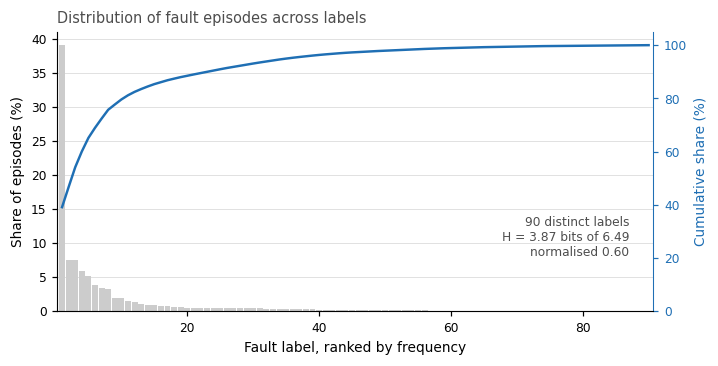

In [ ]:
# FIGURES

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({
    "font.size": 9, "axes.titlesize": 9.5, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.7, "figure.dpi": 110,
})
BLUE, RED, AMBER = "#1f6fb4", "#c0392b", "#e08a1e"

# FIGURE: CATEGORY CONCENTRATION
from scipy.stats import entropy as _ent
vc = ep["fault"].value_counts()
p = vc.values / vc.values.sum()
H = _ent(p, base=2); Hn = H / np.log2(len(p))
cum = np.cumsum(p)

fig, ax = plt.subplots(figsize=(6.6, 3.4))
ax.bar(np.arange(1, len(p) + 1), p * 100, color="0.80", width=0.9, zorder=2)
ax.set_xlabel("Fault label, ranked by frequency")
ax.set_ylabel("Share of episodes (%)")
ax.set_xlim(0.3, len(p) + 0.7)
ax.grid(axis="y", color="0.85", lw=0.5)
ax2 = ax.twinx()
ax2.plot(np.arange(1, len(p) + 1), cum * 100, color=BLUE, lw=1.6, zorder=3)
ax2.set_ylabel("Cumulative share (%)", color=BLUE)
ax2.tick_params(axis="y", colors=BLUE)
ax2.set_ylim(0, 105)
ax2.spines["right"].set_visible(True)
ax2.spines["right"].set_color(BLUE)
ax2.spines["top"].set_visible(False)
ax.annotate(f"{len(p)} distinct labels\nH = {H:.2f} bits of {np.log2(len(p)):.2f}"
            f"\nnormalised {Hn:.2f}", xy=(0.96, 0.2), xycoords="axes fraction", ha="right", fontsize=8, color="0.3")
ax.set_title("Distribution of fault episodes across labels", loc="left", color="0.3")
plt.tight_layout()
plt.savefig(f"{CFG['outdir']}/category_concentration.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{CFG['outdir']}/category_concentration.pdf", bbox_inches="tight")
plt.show();

In [ ]:
# DAILY SERIES WITH OUT-OF-SERVICE DAYS MASKED
import numpy as np, pandas as pd
CFG = dict(episodes="TELEMETRY/build/fault_episodes.csv", outdir="OUTPUT", gap_min_days=7, window=30)
BLUE, RED = "#1f6fb4", "#c0392b"

ep = pd.read_csv(CFG["episodes"], parse_dates=["onset"])
s = (ep.set_index("onset").resample("D").size().asfreq("D").fillna(0).astype(float))
zero = s.eq(0)
block = (zero != zero.shift()).cumsum()
for _, idx in s.groupby(block).groups.items():
    idx = pd.DatetimeIndex(idx)
    if zero.loc[idx].all() and len(idx) >= CFG["gap_min_days"]:
        s.loc[idx] = np.nan

# ROLLING ENTROPY OBTAINED FROM THE SAVED RESULTS
roll = (pd.read_csv(f"{CFG['outdir']}/rolling_entropy.csv", parse_dates=["date"]).set_index("date"))
print(f"{int(s.notna().sum())} observed days, {len(roll)} windows")

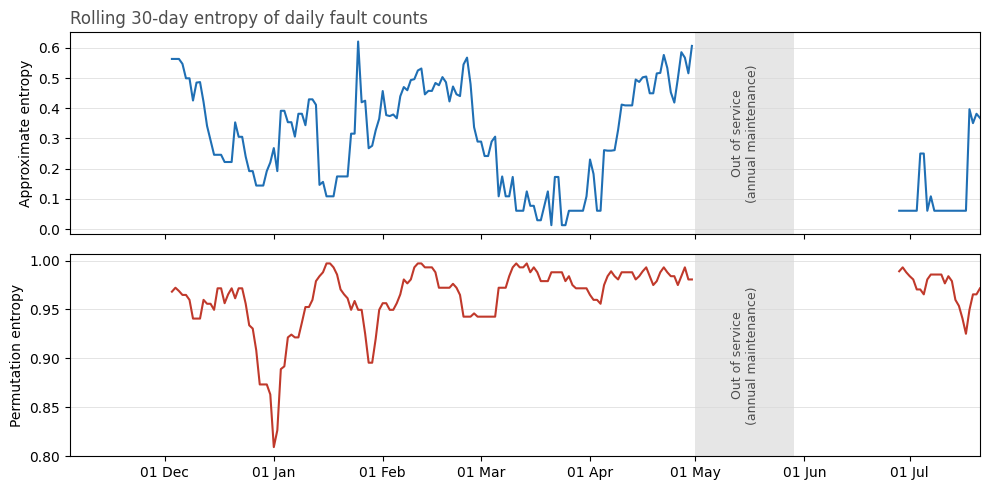

In [ ]:
# FIGURE: ROLLING ENTROPY
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
na = s.isna(); blk = (na != na.shift()).cumsum()
gaps = [(g.index[0], g.index[-1]) for _, g in s.groupby(blk) if na.loc[g.index].all()]

for ax_, col, colr, lab in [(axes[0], "approximate", BLUE, "Approximate entropy"), (axes[1], "permutation", RED, "Permutation entropy")]:
    for si, seg in roll.groupby("segment"):
        ax_.plot(seg.index, seg[col], color=colr, lw=1.5, zorder=4)
    for a, b in gaps:
        ax_.axvspan(a, b, color="0.90", lw=0, zorder=0)
        ax_.text(a + (b - a) / 2, 0.5, "Out of service\n(annual maintenance)", transform=ax_.get_xaxis_transform(), rotation=90,ha="center", va="center", fontsize=9, color="0.3")
    ax_.set_ylabel(lab)
    ax_.grid(axis="y", color="0.85", lw=0.5)

axes[0].set_title(f"Rolling {CFG['window']}-day entropy of daily fault counts", loc="left", color="0.3")
axes[1].xaxis.set_major_locator(mdates.MonthLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[1].set_xlim(s.index[0], s.index[-1])
plt.tight_layout()
plt.savefig(f"{CFG['outdir']}/rolling_entropy.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{CFG['outdir']}/rolling_entropy.pdf", bbox_inches="tight")
plt.show();

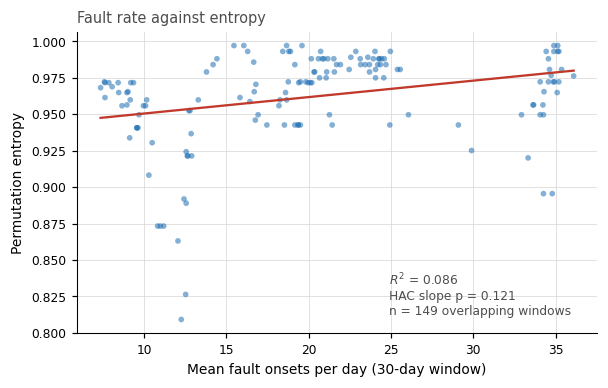

In [ ]:
# FIGURE: RATE VERSUS ENTROPY
import statsmodels.api as sm
d = roll[roll.segment == 0][["rate", "permutation"]].dropna()
X = sm.add_constant(d[["rate"]])
ols = sm.OLS(d["permutation"], X).fit()
hac = ols.get_robustcov_results(cov_type="HAC", maxlags=CFG["window"])
xs = np.linspace(d["rate"].min(), d["rate"].max(), 50)

fig, ax = plt.subplots(figsize=(5.6, 3.6))
ax.scatter(d["rate"], d["permutation"], s=14, color=BLUE, alpha=0.55, edgecolor="none", zorder=3)
ax.plot(xs, ols.params["const"] + ols.params["rate"] * xs, color=RED, lw=1.5, zorder=4)
ax.set_xlabel(f"Mean fault onsets per day ({CFG['window']}-day window)")
ax.set_ylabel("Permutation entropy")
ax.grid(color="0.85", lw=0.5)
ax.set_title("Fault rate against entropy", loc="left", color="0.3")
ax.annotate(f"$R^2$ = {ols.rsquared:.3f}\nHAC slope p = {hac.pvalues[1]:.3f}\n"
            f"n = {len(d)} overlapping windows", xy=(0.6, 0.06), xycoords="axes fraction", fontsize=8, color="0.3")
plt.tight_layout()
plt.savefig(f"{CFG['outdir']}/rate_vs_entropy.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{CFG['outdir']}/rate_vs_entropy.pdf", bbox_inches="tight")
plt.show();

___
**END**